# Иерархические признаки из критической перколяции

Чтобы проверять инструменты интерпретируемости (SAE и т.п.), нужны данные, в которых мы заранее знаем, какие признаки там есть. Обычные игрушечные датасеты для этого слишком простые: признаки в них независимые, а в реальных данных понятия вложены друг в друга (животное -> собака -> такса).

Идея: на пороге перколяции получаются кластеры всех размеров, и каждый кластер можно разбить на подкластеры поменьше. Если считать кластер признаком, получается иерархия признаков, которую мы знаем точно.

Что здесь сделано:
1. Перколяция на квадратной решетке
2. Фазовый переход и порог p_c
3. Распределение размеров кластеров на пороге
4. Фрактальная размерность
5. Разбиение кластеров на подкластеры (дерево)
6. Датасет с признаками из этого дерева

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110})

P_C = 0.592746

## 1. Перколяция на решетке

Решетка L x L, каждая клетка занята с вероятностью p. Соседние (по стороне) занятые клетки образуют кластер.

Генерирую для каждой клетки число u из U(0,1) и считаю клетку занятой, если u < p. Так одно поле u дает конфигурации сразу для всех p, причем при увеличении p клетки только добавляются. Это нужно в пункте 5.

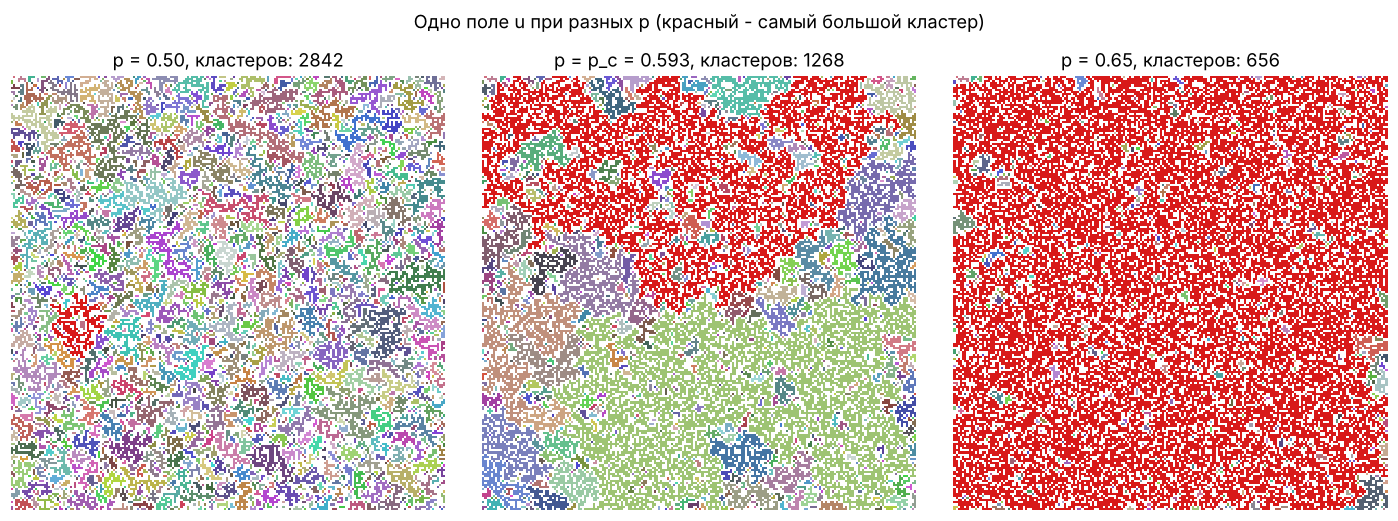

In [2]:
def random_field(L, rng):
    return rng.random((L, L))


def label_clusters(u, p):
    labels, n = ndimage.label(u < p)
    return labels, n


def color_labels(labels, rng):
    n = labels.max()
    colors = rng.uniform(0.25, 0.85, size=(n + 1, 3))
    colors[0] = 1.0
    if n > 0:
        sizes = np.bincount(labels.ravel())
        sizes[0] = 0
        colors[sizes.argmax()] = [0.85, 0.1, 0.1]
    return colors[labels]


L = 200
u = random_field(L, rng)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, p, title in zip(axes, [0.50, P_C, 0.65], ["p = 0.50", f"p = p_c = {P_C:.3f}", "p = 0.65"]):
    labels, n = label_clusters(u, p)
    ax.imshow(color_labels(labels, np.random.default_rng(1)), interpolation="nearest")
    ax.set_title(f"{title}, кластеров: {n}")
    ax.axis("off")
plt.suptitle("Одно поле u при разных p (красный - самый большой кластер)", y=1.02)
plt.tight_layout()
plt.show()

Ниже порога кластеры мелкие, выше порога почти все занято одним большим кластером. На пороге есть кластеры любых размеров, от одной клетки до размера решетки.

## 2. Фазовый переход

Решетка протекает, если есть кластер, который соединяет верхний и нижний край. Смотрю вероятность протекания в зависимости от p для разных L. Чем больше L, тем резче переход около p_c.

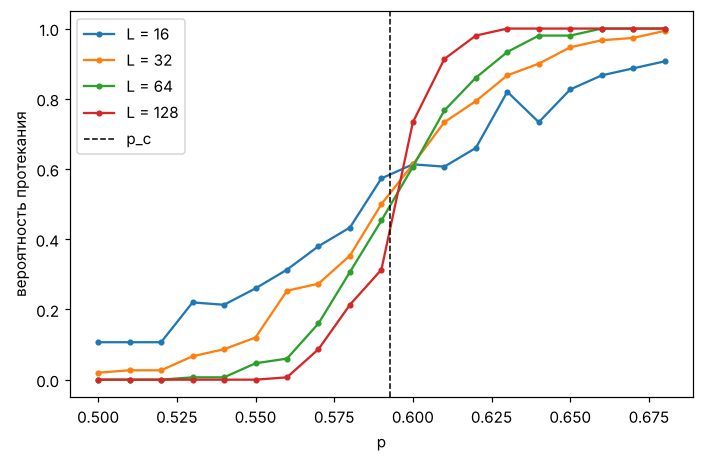

In [3]:
def spans(labels):
    top = set(np.unique(labels[0])) - {0}
    bottom = set(np.unique(labels[-1])) - {0}
    return len(top & bottom) > 0


ps = np.linspace(0.50, 0.68, 19)
n_trials = 150

plt.figure(figsize=(6.5, 4.3))
for L_ in [16, 32, 64, 128]:
    prob = []
    for p in ps:
        hits = sum(spans(label_clusters(random_field(L_, rng), p)[0]) for _ in range(n_trials))
        prob.append(hits / n_trials)
    plt.plot(ps, prob, "o-", ms=3, label=f"L = {L_}")
plt.axvline(P_C, color="k", ls="--", lw=1, label="p_c")
plt.xlabel("p")
plt.ylabel("вероятность протекания")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Размеры кластеров на пороге

n(s) - число кластеров размера s на одну клетку. На пороге должно быть

$$n(s) \propto s^{-\tau}, \quad \tau = 187/91 \approx 2.055$$

То есть типичного размера нет. Похоже на закон Ципфа в реальных данных (частоты слов и т.п.).

Кластеры, которые касаются края решетки, выкидываю, потому что они обрезаны и их размер неправильный.

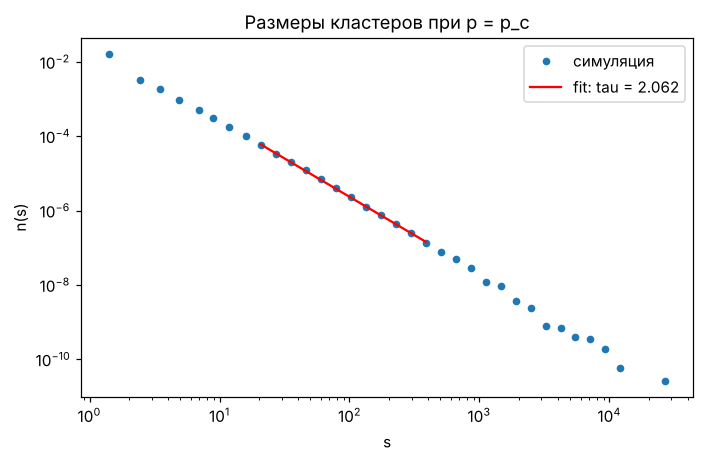

tau = 2.062, теория 2.055


In [4]:
L_big = 512
n_samples = 40
all_sizes = []
for _ in range(n_samples):
    labels, _ = label_clusters(random_field(L_big, rng), P_C)
    s = np.bincount(labels.ravel())
    border = np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))
    s[border] = 0
    s[0] = 0
    all_sizes.append(s[s > 0])
all_sizes = np.concatenate(all_sizes)

bins = np.unique(np.logspace(0, np.log10(all_sizes.max()) + 0.01, 40).astype(int))
counts, edges = np.histogram(all_sizes, bins=bins)
centers = np.sqrt(edges[:-1] * edges[1:])
n_s = counts / np.diff(edges) / (n_samples * L_big**2)

mask = counts > 0
fit = mask & (centers > 20) & (centers < 500)
slope, intercept = np.polyfit(np.log(centers[fit]), np.log(n_s[fit]), 1)

plt.figure(figsize=(6.5, 4.3))
plt.loglog(centers[mask], n_s[mask], "o", ms=4, label="симуляция")
plt.loglog(centers[fit], np.exp(intercept) * centers[fit]**slope, "r-", label=f"fit: tau = {-slope:.3f}")
plt.xlabel("s")
plt.ylabel("n(s)")
plt.title("Размеры кластеров при p = p_c")
plt.legend()
plt.tight_layout()
plt.show()
print(f"tau = {-slope:.3f}, теория {187/91:.3f}")

## 4. Фрактальная размерность

Масса самого большого кластера на пороге растет как M ~ L^D. Для сплошной фигуры было бы D = 2, для перколяции D = 91/48 = 1.896.

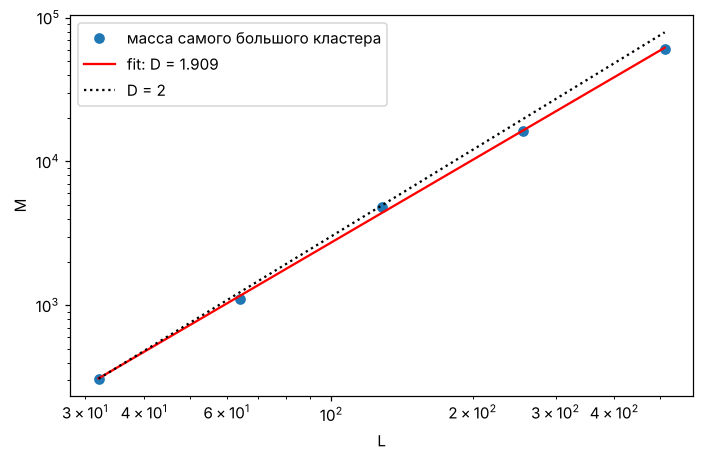

D = 1.909, теория 1.896


In [5]:
Ls = np.array([32, 64, 128, 256, 512])
masses = []
for L_ in Ls:
    m = []
    for _ in range(40):
        labels, _ = label_clusters(random_field(L_, rng), P_C)
        m.append(np.bincount(labels.ravel())[1:].max())
    masses.append(np.mean(m))
masses = np.array(masses)

D, c = np.polyfit(np.log(Ls), np.log(masses), 1)
plt.figure(figsize=(6.5, 4.3))
plt.loglog(Ls, masses, "o", label="масса самого большого кластера")
plt.loglog(Ls, np.exp(c) * Ls**D, "r-", label=f"fit: D = {D:.3f}")
plt.loglog(Ls, masses[0] * (Ls / Ls[0])**2, "k:", label="D = 2")
plt.xlabel("L")
plt.ylabel("M")
plt.legend()
plt.tight_layout()
plt.show()
print(f"D = {D:.3f}, теория {91/48:.3f}")

## 5. Иерархия

Беру несколько уровней p_0 = p_c > p_1 > p_2 > p_3 на одном и том же поле u. Когда p уменьшается, клетки только убираются, поэтому каждый кластер уровня k+1 целиком лежит внутри какого-то кластера уровня k. Получается дерево: кластеры на p_c - корни, подкластеры на p_1 - их дети и т.д.

Чем дальше p от p_c, тем меньше характерный размер кластеров (корреляционная длина ~ |p - p_c|^(-4/3)), так что разные уровни - это разные масштабы.

In [6]:
LEVELS = [P_C, P_C - 0.02, P_C - 0.05, P_C - 0.10]
L_h = 256
u_h = random_field(L_h, np.random.default_rng(7))

level_labels = [label_clusters(u_h, p)[0] for p in LEVELS]


def parent_map(child_labels, parent_labels):
    n_child = child_labels.max()
    parent = np.zeros(n_child + 1, dtype=int)
    occ = child_labels > 0
    parent[child_labels[occ]] = parent_labels[occ]
    pairs = np.unique(np.stack([child_labels[occ], parent_labels[occ]]), axis=1)
    assert pairs.shape[1] == n_child
    return parent


parents = [None] + [parent_map(level_labels[k], level_labels[k - 1]) for k in range(1, len(LEVELS))]
level_sizes = [np.bincount(lab.ravel()) for lab in level_labels]

for k, p in enumerate(LEVELS):
    print(f"уровень {k}: p = {p:.3f}, кластеров {level_labels[k].max()}, самый большой {level_sizes[k][1:].max()}")

уровень 0: p = 0.593, кластеров 1963, самый большой 7449
уровень 1: p = 0.573, кластеров 2411, самый большой 3011
уровень 2: p = 0.543, кластеров 3175, самый большой 961
уровень 3: p = 0.493, кластеров 4620, самый большой 305


Самый большой кластер уровня 0 и его подкластеры на следующих уровнях. Серым - исходный кластер, цветом - подкластеры.

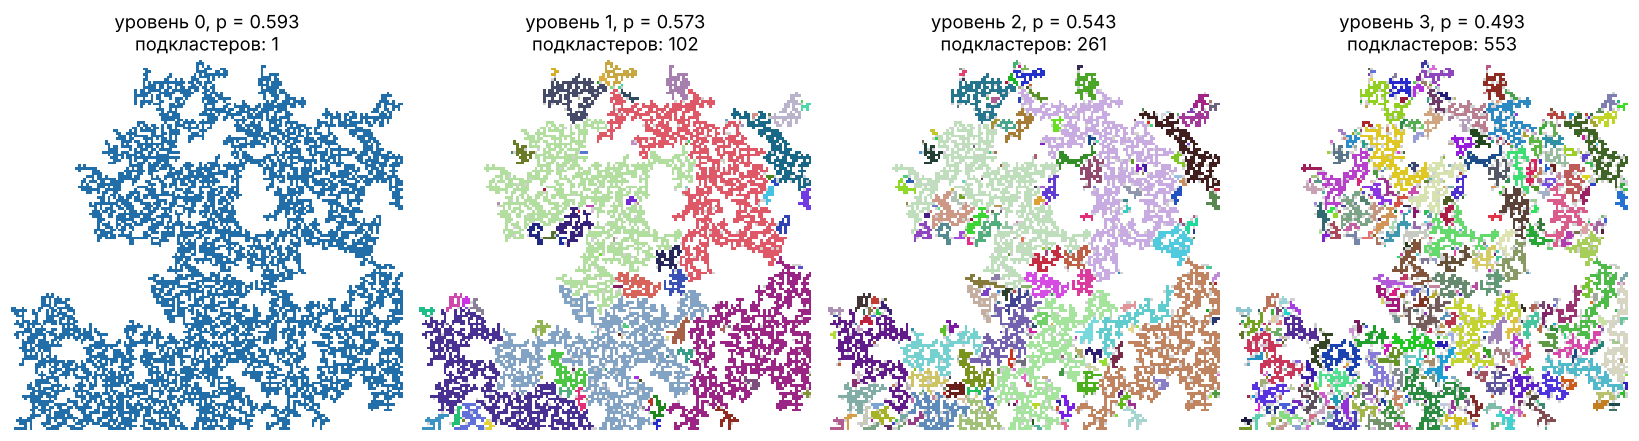

In [7]:
root = level_sizes[0][1:].argmax() + 1
in_root = level_labels[0] == root
ys, xs = np.where(in_root)
crop = (slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))

fig, axes = plt.subplots(1, len(LEVELS), figsize=(15, 4.3))
for k, ax in enumerate(axes):
    img = np.ones(in_root.shape + (3,))
    img[in_root] = 0.82
    lab = np.where(in_root, level_labels[k], 0)
    cols = np.random.default_rng(3).uniform(0.1, 0.9, size=(lab.max() + 1, 3))
    occ = lab > 0
    img[occ] = cols[lab[occ]]
    ax.imshow(img[crop], interpolation="nearest")
    ax.set_title(f"уровень {k}, p = {LEVELS[k]:.3f}\nподкластеров: {len(np.unique(lab)) - 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

То же самое в виде дерева. Оставляю только кластеры размером от MIN_SIZE клеток, иначе ничего не видно.

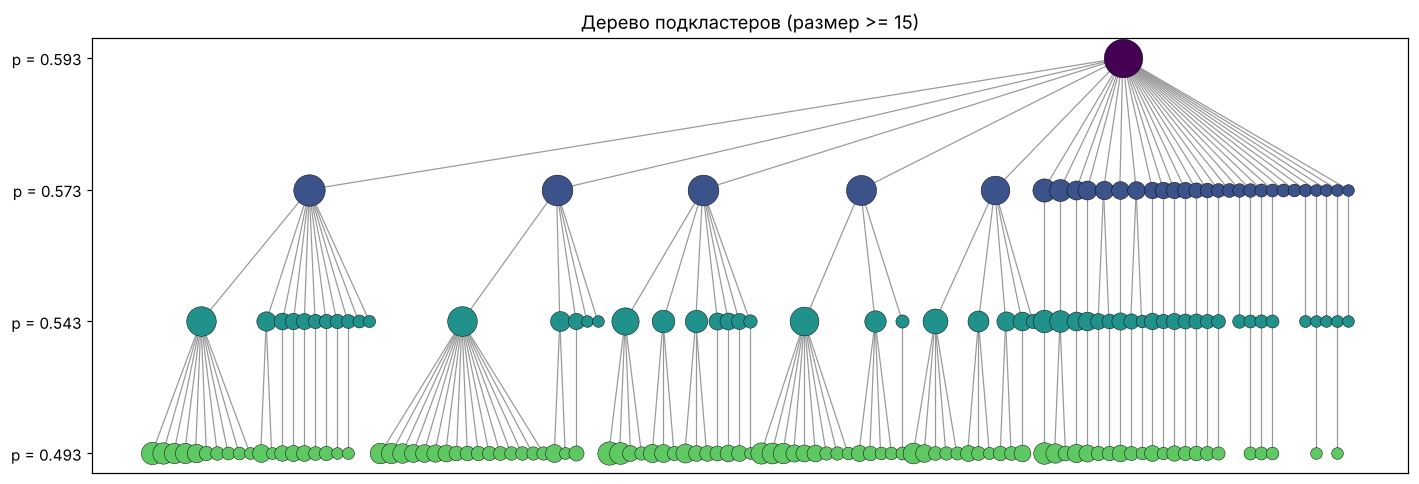

узлов на уровнях: [1, 31, 56, 99]


In [8]:
MIN_SIZE = 15


def children_of(k, node):
    if k + 1 >= len(LEVELS):
        return []
    kids = np.where(parents[k + 1] == node)[0]
    kids = kids[level_sizes[k + 1][kids] >= MIN_SIZE]
    return list(kids[np.argsort(-level_sizes[k + 1][kids])])


pos = {}
tree_edges = []
next_x = [0]


def layout(k, node):
    kids = children_of(k, node)
    if not kids:
        pos[(k, node)] = next_x[0]
        next_x[0] += 1
    else:
        pos[(k, node)] = np.mean([layout(k + 1, c) for c in kids])
        tree_edges.extend(((k, node), (k + 1, c)) for c in kids)
    return pos[(k, node)]


layout(0, root)
plt.figure(figsize=(13, 4.5))
for a, b in tree_edges:
    plt.plot([pos[a], pos[b]], [-a[0], -b[0]], "-", color="0.6", lw=0.8)
for (k, node), x in pos.items():
    s = level_sizes[k][node]
    plt.scatter(x, -k, s=8 * np.log(s)**2, color=plt.cm.viridis(k / len(LEVELS)), zorder=3, edgecolor="k", lw=0.3)
plt.yticks([-k for k in range(len(LEVELS))], [f"p = {p:.3f}" for p in LEVELS])
plt.xticks([])
plt.title(f"Дерево подкластеров (размер >= {MIN_SIZE})")
plt.tight_layout()
plt.show()

print("узлов на уровнях:", [sum(1 for (k, _) in pos if k == lvl) for lvl in range(len(LEVELS))])

Дерево получается неравномерным: у каких-то узлов много детей, у каких-то один-два, размеры детей тоже сильно разные. Это ближе к реальной структуре понятий, чем дерево, где у каждого узла одинаковое число потомков.

## 6. Датасет

- признак = кластер на каком-то уровне (размером от MIN_SIZE)
- пример = случайная занятая клетка
- у примера активны кластеры, в которые попадает клетка (максимум один на уровень)

Что известно заранее:
1. если активен ребенок, то активен и родитель
2. признаки одного уровня не бывают активны одновременно
3. частота признака пропорциональна размеру кластера, поэтому есть несколько частых признаков и много редких

In [9]:
def build_dataset(level_labels, parents, n_points, rng, min_size=MIN_SIZE):
    feat_index, feat_info = {}, []
    for k, lab in enumerate(level_labels):
        sizes = np.bincount(lab.ravel())
        for cid in np.where(sizes >= min_size)[0]:
            if cid == 0:
                continue
            parent_feat = feat_index.get((k - 1, parents[k][cid])) if k > 0 else None
            feat_index[(k, cid)] = len(feat_info)
            feat_info.append({"level": k, "cluster": cid, "size": sizes[cid], "parent": parent_feat})

    occ = np.argwhere(level_labels[0] > 0)
    pts = occ[rng.integers(len(occ), size=n_points)]
    X = np.zeros((n_points, len(feat_info)), dtype=np.uint8)
    for k, lab in enumerate(level_labels):
        cids = lab[pts[:, 0], pts[:, 1]]
        for i, cid in enumerate(cids):
            j = feat_index.get((k, cid))
            if j is not None:
                X[i, j] = 1
    return X, feat_info, pts


X, feat_info, pts = build_dataset(level_labels, parents, n_points=20000, rng=np.random.default_rng(0))
levels_arr = np.array([f["level"] for f in feat_info])
print(f"{X.shape[0]} примеров, {X.shape[1]} признаков")
for k in range(len(LEVELS)):
    print(f"уровень {k}: {np.sum(levels_arr == k)} признаков")
print(f"в среднем активных признаков на пример: {X.sum(1).mean():.2f}")

20000 примеров, 1292 признаков
уровень 0: 155 признаков
уровень 1: 259 признаков
уровень 2: 376 признаков
уровень 3: 502 признаков
в среднем активных признаков на пример: 2.97


Проверка свойств:

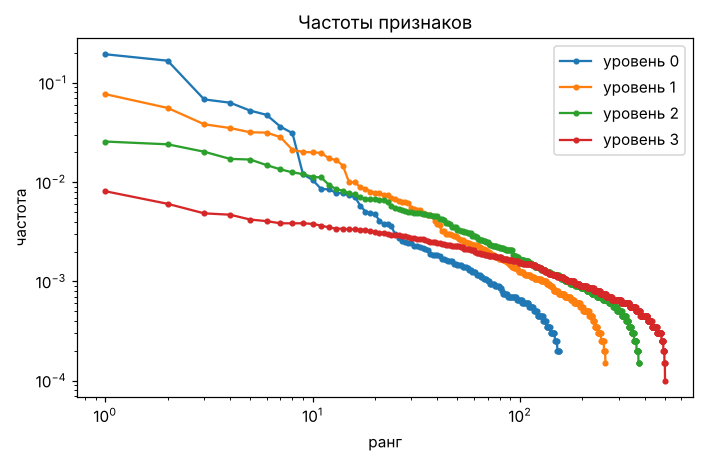

ребенок без родителя: 0
максимум активных признаков одного уровня: 1


In [10]:
violations = 0
for j, f in enumerate(feat_info):
    if f["parent"] is not None:
        violations += np.sum((X[:, j] == 1) & (X[:, f["parent"]] == 0))
print("ребенок без родителя:", violations)

max_per_level = max(X[:, levels_arr == k].sum(1).max() for k in range(len(LEVELS)))
print("максимум активных признаков одного уровня:", max_per_level)

freq = X.mean(0)
plt.figure(figsize=(6.5, 4.3))
for k in range(len(LEVELS)):
    fk = np.sort(freq[levels_arr == k])[::-1]
    fk = fk[fk > 0]
    plt.loglog(np.arange(1, len(fk) + 1), fk, "o-", ms=3, label=f"уровень {k}")
plt.xlabel("ранг")
plt.ylabel("частота")
plt.title("Частоты признаков")
plt.legend()
plt.tight_layout()
plt.show()

В обычных игрушечных датасетах (например, как в Toy Models of Superposition) признаки независимые. Здесь связи между признаками задаются геометрией кластеров, и мы их знаем точно.

In [11]:
np.savez_compressed(
    "percolation_features.npz",
    X=X,
    level=levels_arr,
    parent=np.array([-1 if f["parent"] is None else f["parent"] for f in feat_info]),
    size=np.array([f["size"] for f in feat_info]),
    points=pts,
)

## Дальше

1. Дать каждому признаку случайное направление в R^d, где d меньше числа признаков, и брать x = сумма направлений активных признаков (суперпозиция).
2. Обучить на этом маленькую модель, например автоэнкодер с узким слоем.
3. Обучить SAE на ее активациях и посмотреть, находит ли он признаки всех уровней и не поглощают ли дети родителей (feature absorption).
4. Поменять параметры: число уровней, шаг по p, 3D решетку.